# Praktikum Sub-CPMK-2 &mdash; Perbaikan Citra pada Domain Spasial

**Pengolahan Citra Digital (IF2514505)** &nbsp;|&nbsp; Semester 5 &nbsp;|&nbsp; 1 SKS Praktikum &nbsp;|&nbsp; Durasi sasaran 135 menit (rentang 120&ndash;150)

**Program Studi Informatika &mdash; Institut Teknologi Kalimantan**

---

| | |
|---|---|
| **Nama** | Muhammad Wisnu Wardhana |
| **NIM** | 11241063 |
| **Kelas / Kelompok** | kelas A |
| **Tanggal praktikum** | Rabu 4 november 2026 |

---

### Capaian yang diukur
**Sub-CPMK-2**: Mahasiswa mampu menerapkan teknik perbaikan citra pada domain spasial termasuk histogram equalization.

### Rujukan utama
Gonzalez, R.C. dan Woods, R.E. (2018) *Digital Image Processing*, edisi ke-4, Bab 3 (§3.1&ndash;3.6). Nomor persamaan pada notebook ini mengikuti buku tersebut.

### Petunjuk pengerjaan
1. Jalankan sel secara berurutan. Sel bertanda `# TODO` wajib Anda lengkapi sendiri.
2. Setiap blok **Analisis** diisi kalimat Anda sendiri dan **wajib memuat angka** dari keluaran Anda.
3. Citra uji dibangkitkan di dalam notebook (benih acak tetap) &mdash; **tidak perlu mengunggah berkas apa pun**.
4. Bagian bertanda **[Pengayaan]** boleh dilewati bila waktu tidak cukup; jalur inti selesai dalam &plusmn;120 menit.
5. Kumpulkan notebook dalam keadaan **sudah dijalankan penuh** dengan nama `PraktikumPCD_SubCPMK2_NIM_Nama.ipynb`.

| Bagian | Isi | Menit |
|---|---|---|
| 0 | Persiapan dan citra uji | 10 |
| 1 | Transformasi intensitas melalui tabel penelusuran (§3.2) | 25 |
| 2 | Histogram equalization, spesifikasi, dan CLAHE (§3.3) | 35 |
| 3 | Penapisan spasial: korelasi, penghalusan, penajaman (§3.4&ndash;3.6) | 40 |
| 4 | Studi kasus mini: citra perairan berkabut | 15 |
| 5 | Pemeriksaan akhir dan pengumpulan | 10 |


## Bagian 0 &mdash; Persiapan (10 menit)
Sel berikut memuat pustaka, fungsi bantu, dan pembangkit citra uji. **Jalankan tanpa diubah.**

NumPy 2.4.6 | OpenCV 5.0.0
redup     (256, 256) uint8 min 41 maks 114
dokumen   (240, 320) uint8 min 3 maks 251
bersih    (256, 256) uint8 min 8 maks 251
berderau  (256, 256) uint8 min 0 maks 255
perairan  (240, 360) uint8 min 89 maks 203


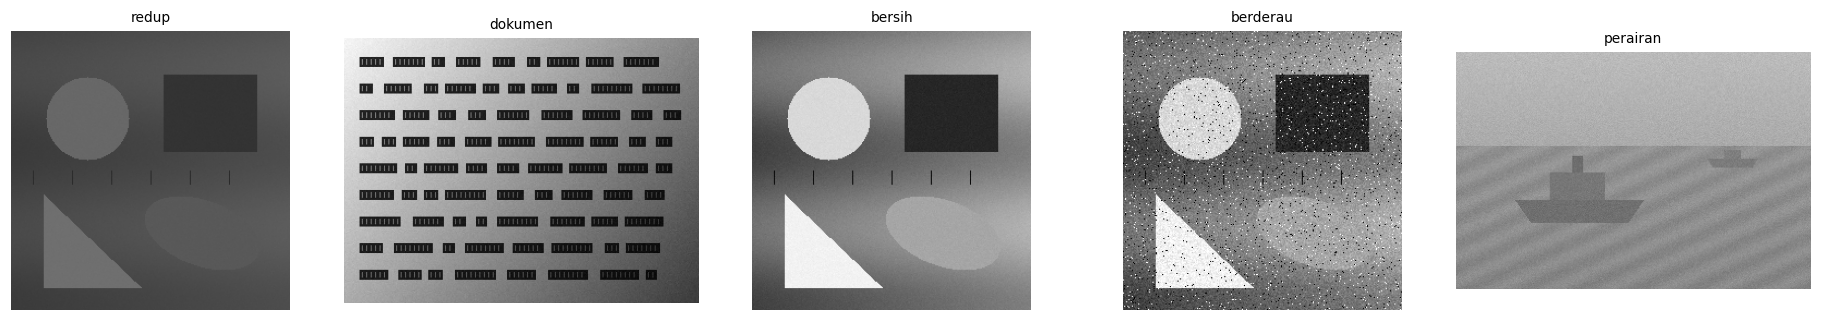

In [ ]:
# Sel persiapan — jalankan tanpa diubah
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time

plt.rcParams['figure.dpi'] = 110
print('NumPy', np.__version__, '| OpenCV', cv2.__version__)

"""Pembangkit citra uji sintetis (benih acak tetap, hanya NumPy).

Hanya memakai NumPy (tanpa fungsi gambar OpenCV) agar citra identik di versi
OpenCV mana pun. Seluruh citra bebas persoalan lisensi dan reprodusibel.
"""
import numpy as np

BENIH = 2026


def _grid(h, w):
    return np.mgrid[0:h, 0:w].astype(np.float64)


def _adegan(rng, h=256, w=256):
    """Adegan dasar: gradasi, lingkaran, persegi, elips, segitiga, garis halus (float 0..1)."""
    yy, xx = _grid(h, w)
    img = 0.35 + 0.25 * (xx / w) + 0.10 * np.sin(yy / 23.0)
    img[(xx - 70) ** 2 + (yy - 80) ** 2 <= 38 ** 2] = 0.85                    # lingkaran terang
    img[(yy >= 40) & (yy <= 110) & (xx >= 140) & (xx <= 225)] = 0.15          # persegi gelap
    u, v = xx - 175, yy - 185
    t = np.deg2rad(20)
    ue, ve = u * np.cos(t) + v * np.sin(t), -u * np.sin(t) + v * np.cos(t)
    img[(ue / 55) ** 2 + (ve / 30) ** 2 <= 1] = 0.65                          # elips
    img[(yy >= 150) & (yy <= 235) & (xx >= 30) & (xx <= 30 + (yy - 150) * 1.05)] = 0.95  # segitiga
    for i in range(6):                                                          # rincian halus
        img[128:141, 20 + 36 * i] = 0.05
    img += rng.normal(0, 0.01, img.shape)
    return np.clip(img, 0, 1)


def citra_redup(rng):
    """Kontras rendah: intensitas termampatkan ke rentang sempit (kira-kira 40..115)."""
    return np.clip(40 + 75 * _adegan(rng), 0, 255).round().astype(np.uint8)


def dokumen_tak_merata(rng, h=240, w=320):
    """'Baris teks' gelap di atas kertas terang, pencahayaan dari kiri atas."""
    img = np.full((h, w), 0.92)
    for b in range(9):                                    # 9 baris teks
        y0 = 18 + 24 * b
        x = 14
        while x < w - 20:
            pj = int(rng.integers(10, 38))                # panjang 'kata'
            if x + pj > w - 14:
                break
            img[y0:y0 + 9, x:x + pj] = 0.14
            img[y0 + 2:y0 + 7, x + 2:x + pj - 2:4] = 0.55  # celah antarhuruf
            x += pj + int(rng.integers(6, 12))
    yy, xx = _grid(h, w)
    cahaya = 1.05 - 0.80 * ((xx / w) * 0.6 + (yy / h) * 0.4)
    img = img * cahaya + rng.normal(0, 0.012, (h, w))
    return np.clip(255 * img, 0, 255).round().astype(np.uint8)


def citra_bersih(rng):
    """Kebenaran dasar untuk uji penapis (rentang penuh)."""
    return np.clip(255 * _adegan(rng), 0, 255).round().astype(np.uint8)


def beri_derau(img, rng, sigma=12.0, p_sp=0.04):
    """Derau Gaussian (sigma) ditambah derau garam-merica (proporsi p_sp)."""
    g = img.astype(np.float64) + rng.normal(0, sigma, img.shape)
    u = rng.random(img.shape)
    g[u < p_sp / 2] = 0
    g[(u >= p_sp / 2) & (u < p_sp)] = 255
    return np.clip(g, 0, 255).round().astype(np.uint8)


def perairan_berkabut(rng, h=240, w=360):
    """Langit, laut bergelombang, dua kapal, kabut (kontras rendah), derau sensor."""
    yy, xx = _grid(h, w)
    cak = 95
    langit = 0.78 - 0.15 * (yy / cak)
    laut = 0.42 + 0.06 * np.sin(xx / 9.0 + yy / 4.0) - 0.10 * ((yy - cak) / (h - cak))
    img = np.where(yy < cak, langit, laut)
    # kapal besar: lambung trapesium + bangunan + cerobong
    lambung = (yy >= 150) & (yy <= 172) & (xx >= 60 + (yy - 150) * 0.7) & (xx <= 190 - (yy - 150) * 0.7)
    img[lambung] = 0.12
    img[(yy >= 122) & (yy < 150) & (xx >= 95) & (xx <= 150)] = 0.18
    img[(yy >= 105) & (yy < 122) & (xx >= 118) & (xx <= 128)] = 0.10
    # kapal kecil di kejauhan
    img[(yy >= 108) & (yy <= 116) & (xx >= 255 + (yy - 108) * 0.6) & (xx <= 305 - (yy - 108) * 0.6)] = 0.22
    img[(yy >= 99) & (yy < 108) & (xx >= 272) & (xx <= 288)] = 0.25
    kabut = 0.55
    img = (1 - kabut) * img + kabut * 0.70
    img += rng.normal(0, 0.018, img.shape)
    return np.clip(255 * img, 0, 255).round().astype(np.uint8)


def masker_perairan(h=240, w=360):
    """Masker kebenaran dasar: (kapal, laut). Laut = di bawah cakrawala, di luar kapal, dengan jarak aman."""
    yy, xx = _grid(h, w)
    kapal = np.zeros((h, w), bool)
    kapal |= (yy >= 150) & (yy <= 172) & (xx >= 60 + (yy - 150) * 0.7) & (xx <= 190 - (yy - 150) * 0.7)
    kapal |= (yy >= 122) & (yy < 150) & (xx >= 95) & (xx <= 150)
    kapal |= (yy >= 105) & (yy < 122) & (xx >= 118) & (xx <= 128)
    kapal |= (yy >= 108) & (yy <= 116) & (xx >= 255 + (yy - 108) * 0.6) & (xx <= 305 - (yy - 108) * 0.6)
    kapal |= (yy >= 99) & (yy < 108) & (xx >= 272) & (xx <= 288)
    sekitar = np.zeros_like(kapal)
    sekitar[95:185, 45:205] = True
    sekitar[92:125, 245:315] = True
    laut = (yy >= 100) & ~sekitar
    return kapal, laut


def bangkitkan_semua():
    rng = np.random.default_rng(BENIH)
    redup = citra_redup(rng)
    dok = dokumen_tak_merata(rng)
    bersih = citra_bersih(rng)
    berderau = beri_derau(bersih, rng)
    laut = perairan_berkabut(rng)
    return {"redup": redup, "dokumen": dok, "bersih": bersih, "berderau": berderau, "perairan": laut}

def tampil(daftar, judul=None, kolom=None, tinggi=3.0):
    n = len(daftar); kolom = kolom or n; baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(3.4 * kolom, tinggi * baris))
    ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis('off')
    for a, im, t in zip(ax, daftar, judul or [''] * n):
        a.imshow(im, cmap='gray', vmin=0, vmax=255); a.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

def gambar_hist(ax, im, judul=''):
    h = np.bincount(im.ravel(), minlength=256)
    ax.bar(np.arange(256), h, width=1.0, color='#16324F')
    a2 = ax.twinx(); a2.plot(np.cumsum(h) / h.sum(), color='#C2680E', lw=1.5, ls='--'); a2.set_ylim(0, 1.05)
    ax.set_title(judul, fontsize=9); ax.set_xlim(-2, 257)

def entropi(im):
    h = np.bincount(im.ravel(), minlength=256).astype(float); p = h[h > 0] / h.sum()
    return float(-(p * np.log2(p)).sum())

def psnr(acuan, uji):
    mse = np.mean((acuan.astype(float) - uji.astype(float)) ** 2)
    return float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

def ringkas(nama, im):
    print(f'{nama:24s} rerata {im.mean():7.2f}  std {im.std():6.2f}  min {im.min():3d}  maks {im.max():3d}'
          f'  aras {len(np.unique(im)):3d}  entropi {entropi(im):.4f}')

C = bangkitkan_semua()
redup, dok, bersih, berderau, perairan = C['redup'], C['dokumen'], C['bersih'], C['berderau'], C['perairan']
kabur = cv2.GaussianBlur(bersih, (9, 9), 1.5)   # masukan untuk Bagian 3.3
for k, v in C.items(): print(f'{k:9s}', v.shape, v.dtype, 'min', v.min(), 'maks', v.max())
tampil([redup, dok, bersih, berderau, perairan], list(C.keys()))

## Bagian 1 &mdash; Transformasi intensitas melalui tabel penelusuran (25 menit)

Transformasi intensitas $s = T(r)$ (Gonzalez Eq. 3-2) hanya bergantung pada nilai piksel itu sendiri. Karena masukan 8-bit hanya memiliki 256 kemungkinan nilai, $T$ cukup dihitung **sekali** untuk 256 aras lalu disimpan sebagai *lookup table* (LUT); penerapannya cukup dengan pengindeksan `lut[img]`.

Rumus yang dipakai: negatif $s = L-1-r$ (Eq. 3-3), logaritmik $s = c\log(1+r)$ (Eq. 3-4), dan pangkat $s = c\,r^{\gamma}$ (Eq. 3-5) yang di sini ditulis dalam bentuk ternormalisasi $s = 255\,(r/255)^{\gamma}$.

**Aturan pembulatan modul ini:** $\lfloor x + 0{,}5 \rfloor$ (setengah dibulatkan ke atas). Jangan memakai `np.round`, yang membulatkan 2,5 menjadi 2.

In [ ]:
# TODO 1.1 — LUT negatif, logaritmik, gamma
r = np.arange(256, dtype=np.float64)

def bulat(x):
    return np.floor(x + 0.5)

def lut_negatif():
    return bulat(255 - r).astype(np.uint8)

def lut_log():
    c = 255 / np.log(256)          # agar r = 255 dipetakan ke 255
    return bulat(c * np.log1p(r)).astype(np.uint8)

def lut_gamma(g):
    return bulat(255 * (r / 255) ** g).astype(np.uint8)

# Uji cepat terhadap hitungan tangan (harus True semua)
print(lut_negatif()[0] == 255, lut_gamma(0.5)[64] == 128, lut_gamma(2.0)[64] == 16, lut_log()[10] == 110)

True True True True


asli                     rerata   78.54  std  15.27  min  41  maks 114  aras  62  entropi 5.3350
gamma 0,5                rerata  140.85  std  13.77  min 102  maks 170  aras  56  entropi 5.1646
gamma 2,0                rerata   25.07  std   9.65  min   7  maks  51  aras  38  entropi 4.6069
min-maks                 rerata  131.16  std  53.44  min   0  maks 255  aras  62  entropi 5.3350
sepotong                 rerata  119.12  std  65.64  min  14  maks 237  aras  44  entropi 5.0112


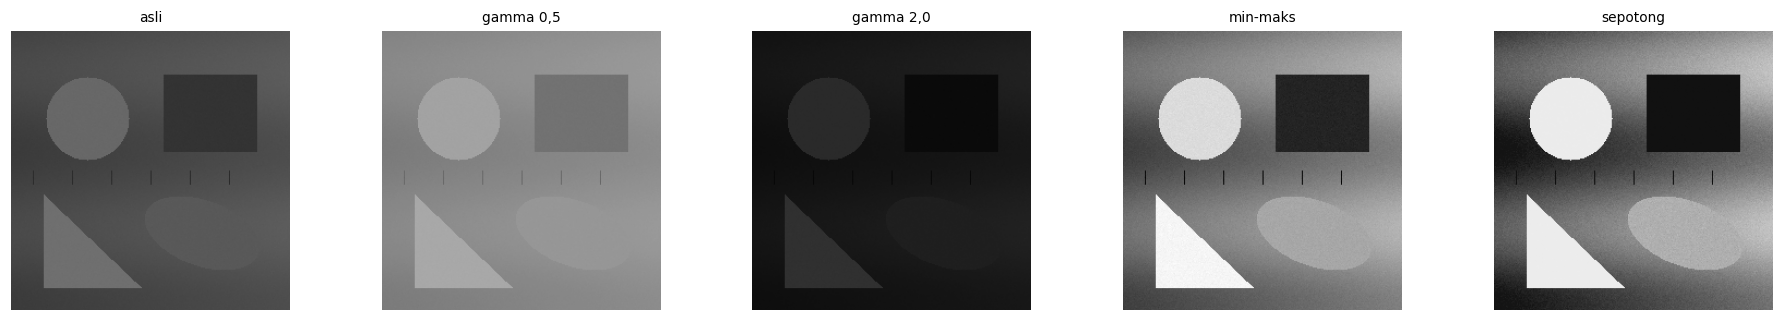

aras asli: 62 | aras setelah redup/4: 20


In [ ]:
# TODO 1.2 — Peregangan kontras
def lut_minmaks(im):
    lo, hi = float(im.min()), float(im.max())
    return bulat(np.clip((r - lo) / (hi - lo) * 255, 0, 255)).astype(np.uint8)

def lut_sepotong(r1, s1, r2, s2):
    return bulat(np.interp(r, [0, r1, r2, 255], [0, s1, s2, 255])).astype(np.uint8)

hasil1 = {
    'asli': redup,
    'gamma 0,5': lut_gamma(0.5)[redup],
    'gamma 2,0': lut_gamma(2.0)[redup],
    'min-maks': lut_minmaks(redup)[redup],
    'sepotong': lut_sepotong(60, 20, 100, 235)[redup],
}
for k, v in hasil1.items():
    ringkas(k, v)
tampil(list(hasil1.values()), list(hasil1.keys()))

# Bukti Analisis 1(c): rentang keluaran sempit (redup / 4)
print('aras asli:', len(np.unique(redup)), '| aras setelah redup/4:', len(np.unique(bulat(redup / 4.0))))

In [ ]:
# TODO 1.3 — LUT vs perhitungan langsung pada citra 2000x2000
besar = np.tile(redup, (8, 8))[:2000, :2000]
lut = lut_gamma(0.5)
langsung = lambda: bulat(255 * (besar / 255.0) ** 0.5).astype(np.uint8)

def ukur(f, n=10):
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); f(); t.append(time.perf_counter() - t0)
    return min(t)

print('Ukuran:', besar.shape, '| hasil identik:', np.array_equal(lut[besar], langsung()))
t_lut, t_lgs = ukur(lambda: lut[besar]), ukur(langsung)
print(f'LUT {t_lut*1e3:.2f} ms | langsung {t_lgs*1e3:.2f} ms | nisbah {t_lgs/t_lut:.1f}x')

Ukuran: (2000, 2000) | hasil identik: True
LUT 8.42 ms | langsung 25.83 ms | nisbah 3.1x


**Analisis 1.** (a) Pada citra `redup`, gamma 0,5 menaikkan rerata tetapi simpangan bakunya justru turun. Jelaskan dengan bentuk kurva gamma pada rentang masukan citra ini (lihat nilai min&ndash;maks Anda). (b) Peregangan min&ndash;maks menaikkan simpangan baku berlipat, tetapi jumlah aras dan entropi tidak berubah. Mengapa? (c) Apa yang terjadi pada jumlah aras bila rentang keluaran lebih sempit daripada rentang masukan?

*Jawaban Anda:*

**(a)** Rentang masukan `edup sempit, yaitu 41–114 lebar 73 Gamma 0,5 mencerahkan semua piksel sehingga rerata naik dari 78,54 menjadi 140,85. Namun kurva pangkat 0,5 makin melandai ke arah aras tinggi, sehingga piksel yang sudah terang bertambah lebih sedikit daripada piksel gelap. Rentangnya menyempit dari 41–114 lebar 73 menjadi 102–170 lebar 68, dan std turun dari 15,27 menjadi 13,77

**(b)** Min–maks adalah pemetaan linear: semua nilai ditarik dengan faktor yang sama dari rentang 41–114 menjadi 0–255, sehingga std naik dari 15,27 menjadi 53,44. Jumlah aras 62 dan entropi 5,3350 tidak berubah karena pemetaan itu satu-ke-satu, jadi tidak ada aras yang bergabung, dan entropi hanya bergantung pada proporsi piksel tiap aras, bukan pada nilai arasnya

**(c)** Aras yang berbeda bergabung terpetakan ke nilai yang sama setelah pembulatan sehingga jumlah aras berkurang dan informasi hilang, menurunkan jumlah aras dari 62 menjadi 20. Gamma 2,0 keluaran 7–51 menurunkannya menjadi 38, dan entropi turun ke 4,6069

## Bagian 2 &mdash; Histogram equalization, spesifikasi, dan CLAHE (35 menit)

Bentuk diskret histogram equalization (Gonzalez Eq. 3-15):

$$s_k = T(r_k) = (L-1)\sum_{j=0}^{k} p_r(r_j), \qquad p_r(r_j) = \frac{n_j}{MN}$$

In [ ]:
# TODO 2.1 — Eq. 3-15 sebagai LUT
def lut_he(im, L=256):
    h = np.bincount(im.ravel(), minlength=L)
    return bulat((L - 1) * np.cumsum(h) / im.size).astype(np.uint8)

n_contoh = [10, 20, 14, 8, 5, 4, 2, 1]
contoh = np.repeat(np.arange(8), n_contoh).reshape(8, 8).astype(np.uint8)
print(lut_he(contoh, L=8)[:8])   # harus [1 3 5 6 6 7 7 7]

[1 3 5 6 6 7 7 7]


In [ ]:
# TODO 2.2 — Bandingkan dengan cv2.equalizeHist
for nama, im in [('redup', redup), ('berderau', berderau)]:
    a, b = lut_he(im)[im], cv2.equalizeHist(im)
    print(f'{nama:9s} piksel beda: {(a != b).sum():6d} | selisih maks: {np.abs(a.astype(int) - b.astype(int)).max()}'
          f' | piksel aras 0: {(im == 0).sum()} | aras terendah terisi: {im.min()}')

redup     piksel beda:      0 | selisih maks: 0 | piksel aras 0: 0 | aras terendah terisi: 41
berderau  piksel beda:  59713 | selisih maks: 6 | piksel aras 0: 1372 | aras terendah terisi: 0


**Analisis 2.1.** Pada salah satu citra, hasil Anda identik dengan pustaka; pada citra lain berbeda pada puluhan ribu piksel. Periksa histogram `berderau` pada aras 0, lalu rumuskan dugaan tentang rumus yang dipakai `cv2.equalizeHist`. **Uji dugaan Anda** dengan menulis varian `lut_he_cdfmin` di sel berikut hingga selisihnya nol pada kedua citra. Apakah ini berarti implementasi Eq. 3-15 Anda salah?

*Jawaban Anda:*

Pada redup hasil saya identik dengan cv2.equalizeHist 0 piksel beda Pada berderau ada 59.713 piksel beda dengan selisih maksimum 6. Penyebabnya, berderau punya 1.372 piksel di aras 0 derau garam-merica sehingga Eq. 3-15 memetakan aras 0 ke sekitar 5, bukan 0. Pada redup, aras terendah 41 hampir kosong, jadi efeknya hilang

Dugaan saya: cv2.equalizeHist mengurangkan cdf_min CDF pada aras terendah yang terisi sebelum dinormalkan Setelah ditulis sebagai lut_he_cdfmin, selisihnya 0 piksel pada kedua citra, jadi dugaan terbukti untuk dua citra ini

Implementasi Eq. 3-15 saya tidak salah: lolos contoh 8 aras dan identik pada `redup`. Keduanya hanyalah dua definisi diskret yang berbeda; varian `cdf_min` memastikan aras terendah menjadi 0.

In [ ]:
# TODO 2.3 — Varian dengan cdf_min
def lut_he_cdfmin(im, L=256):
    c = np.cumsum(np.bincount(im.ravel(), minlength=L))
    cmin = c[c > 0][0]
    return bulat((c - cmin) / (im.size - cmin) * (L - 1)).clip(0, L - 1).astype(np.uint8)

for nama, im in [('redup', redup), ('berderau', berderau)]:
    print(nama, 'piksel beda:', (lut_he_cdfmin(im)[im] != cv2.equalizeHist(im)).sum())

redup piksel beda: 0
berderau piksel beda: 0


### 2.4 Spesifikasi histogram (*histogram matching*)

Langkah diskret menurut Gonzalez (Eq. 3-20 s.d. 3-23): (1) hitung $s_k$ dengan Eq. 3-15; (2) hitung $G(z_q) = (L-1)\sum_{i=0}^{q} p_z(z_i)$ dari histogram sasaran dan bulatkan; (3) untuk setiap $s_k$ cari $z_q$ dengan $G(z_q)$ **terdekat**; bila ada lebih dari satu, **pilih yang terkecil**.

In [ ]:
# TODO 2.4 — Spesifikasi histogram
def lut_spesifikasi(im, pz, L=256):
    S = bulat((L - 1) * np.cumsum(np.bincount(im.ravel(), minlength=L)) / im.size)
    G = bulat((L - 1) * np.cumsum(np.asarray(pz, float) / np.sum(pz)))
    return np.array([np.argmin(np.abs(G - s)) for s in S], dtype=np.uint8)   # argmin: seri -> indeks terkecil

pz_contoh = np.array([0, 2, 6, 10, 14, 16, 10, 6]) / 64
print(lut_spesifikasi(contoh, pz_contoh, L=8)[:8])   # harus [2 3 5 6 6 7 7 7]

[2 3 5 6 6 7 7 7]


In [ ]:
# [Pengayaan] TODO 2.5 — Sasaran Gaussian (rerata 128, sb 40)
z = np.arange(256)
pg = np.exp(-0.5 * ((z - 128) / 40) ** 2); pg /= pg.sum()
he_r, sp_r = lut_he(redup)[redup], lut_spesifikasi(redup, pg)[redup]
print('sasaran: rerata', (z * pg).sum().round(2), 'std', np.sqrt((((z - 128) ** 2) * pg).sum()).round(2))
for n, im in [('asli', redup), ('HE biasa', he_r), ('spesifikasi', sp_r)]: ringkas(n, im)

sasaran: rerata 127.99 std 39.69
asli                     rerata   78.54  std  15.27  min  41  maks 114  aras  62  entropi 5.3350
HE biasa                 rerata  131.07  std  73.64  min   0  maks 255  aras  48  entropi 5.3132
spesifikasi              rerata  129.90  std  39.61  min   0  maks 239  aras  48  entropi 5.3132


### 2.6 Ekualisasi lokal: CLAHE
Gonzalez §3.3 membahas ekualisasi lokal dengan jendela bergeser. CLAHE (Zuiderveld, 1994) adalah varian praktis: ekualisasi per ubin, histogram dipotong pada `clipLimit`, lalu antar-ubin diinterpolasi bilinear. CLAHE **tidak dibahas rinci** di Gonzalez; perlakukan sebagai pengayaan.

                kiri-atas  kanan-bawah  selisih     std  entropi
asli               179.90        75.87   104.03   62.36   7.5480
HE global          201.54        57.00   144.54   73.52   7.4016
CLAHE clip 1       180.27        88.91    91.36   62.27   7.4919
CLAHE clip 2       172.17        97.14    75.03   59.12   7.4025
CLAHE clip 4       164.09       106.02    58.07   57.69   7.3512
CLAHE clip 8       151.13       119.66    31.48   60.03   7.4624


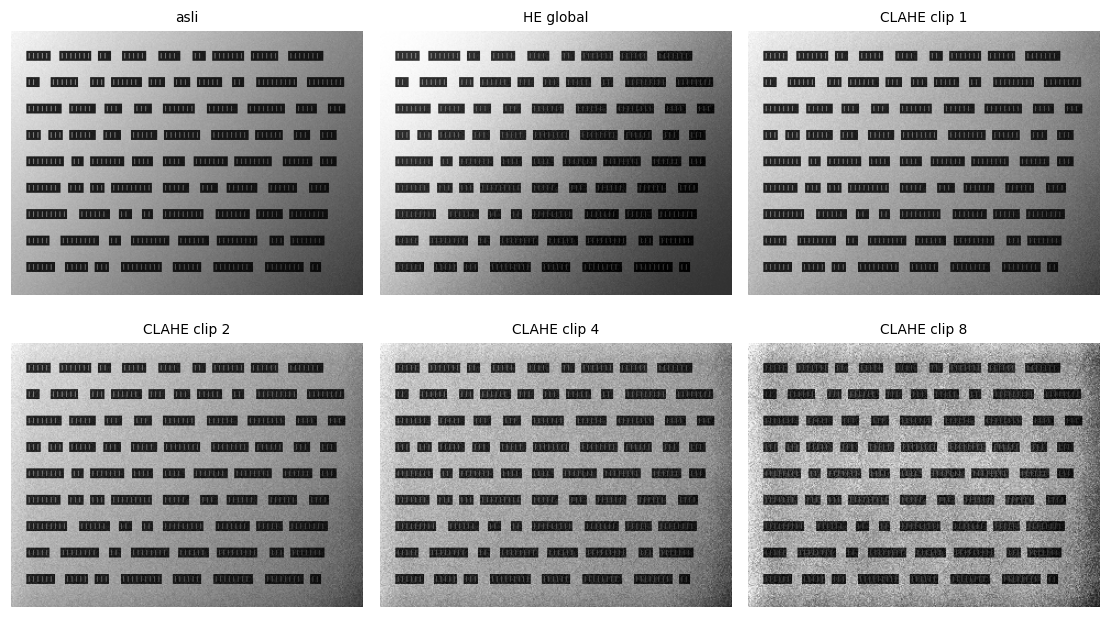

In [ ]:
# TODO 2.6 — HE global vs CLAHE pada dok
hasil = [('asli', dok), ('HE global', cv2.equalizeHist(dok))]
for cl in [1, 2, 4, 8]:
    hasil.append((f'CLAHE clip {cl}', cv2.createCLAHE(clipLimit=cl, tileGridSize=(8, 8)).apply(dok)))
print(f'{"":14s} {"kiri-atas":>10s} {"kanan-bawah":>12s} {"selisih":>8s} {"std":>7s} {"entropi":>8s}')
for nama, im in hasil:
    a, b = im[:80, :100].mean(), im[160:, 220:].mean()
    print(f'{nama:14s} {a:10.2f} {b:12.2f} {a - b:8.2f} {im.std():7.2f} {entropi(im):8.4f}')
tampil([im for _, im in hasil], [n for n, _ in hasil], kolom=3)

**Analisis 2.2.** (a) Dengan angka daerah kanan-bawah, tunjukkan mengapa HE global gagal pada citra berpencahayaan tak merata. (b) Tetapkan satu clipLimit untuk `dok` dan justifikasi dengan angka, bukan kesan visual. Ingat: entropi yang lebih tinggi tidak otomatis lebih baik bila yang naik adalah derau latar. (c) Sebutkan satu jenis citra yang **tidak boleh** diekualisasi bila nilai pikselnya akan diukur, dan mengapa.

*Jawaban Anda:*

**(a)** Di kanan-bawah kertas gelap rerata turun dari 75,87 menjadi 57,00 setelah HE global, sedangkan kiri-atas naik dari 179,90 menjadi 201,54. Selisih keduanya melebar dari 104,03 menjadi 144,54. HE global memakai satu pemetaan untuk seluruh citra, dan pemetaan itu ditentukan oleh piksel kertas terang yang paling banyak, sehingga daerah gelap tidak terbantu.

**(b)** Saya pilih clipLimit = 2 Selisih kiri-atas dan kanan-bawah turun dari 104,03 menjadi 75,03, dengan std 59,12 dan entropi 7,4025 yang tidak melonjak. Clip 8 meratakan lebih jauh selisih 31,48 tetapi entropinya naik lagi ke 7,4624 dan std ke 60,03, yang menandakan derau latar ikut diperkuat. Ini adalah kompromi: clip 1 terlalu sedikit meratakan selisih 91,36 clip 4 dan 8 mulai menguatkan derau.

**(c)** Citra yang nilai pikselnya adalah ukuran fisik, misalnya citra termal nilai piksel = suhu atau CT. HE mengubah nilai dengan pemetaan nonlinier yang bergantung pada histogram citra itu sendiri, dan menggabungkan aras. Pada redup 62 aras turun menjadi 48 aras setelah HE, sehingga nilai aslinya tidak bisa dipulihkan dan antarcitra tidak bisa dibandingkan.

## Bagian 3 &mdash; Penapisan spasial (40 menit)

Korelasi (Gonzalez Eq. 3-31): $g(x,y) = \sum_{s=-a}^{a}\sum_{t=-b}^{b} w(s,t)\,f(x+s,\,y+t)$. Konvolusi (Eq. 3-35) sama, tetapi kernel diputar 180&deg; lebih dahulu. Catatan: `cv2.filter2D` melaksanakan **korelasi**.

In [ ]:
# TODO 3.1 — Korelasi 3x3 dengan padding replikasi
def korelasi3(f, w):
    f = f.astype(np.float64); H, W = f.shape
    p = np.pad(f, 1, mode='edge'); g = np.zeros_like(f)
    for s in range(3):
        for t in range(3):
            g += w[s, t] * p[s:s + H, t:t + W]
    return g

bf = bersih.astype(np.float64)
w_tak_setangkup = np.array([[1, 0, 0], [0, 0, 0], [0, 0, 2]], float)
print('selisih maks vs filter2D:',
      np.abs(korelasi3(bf, w_tak_setangkup) - cv2.filter2D(bf, -1, w_tak_setangkup, borderType=cv2.BORDER_REPLICATE)).max())

jendela = np.array([[10, 20, 30], [40, 50, 60], [70, 80, 90]], float)
print('korelasi', korelasi3(jendela, w_tak_setangkup)[1, 1], '| konvolusi', korelasi3(jendela, np.flip(w_tak_setangkup))[1, 1])

selisih maks vs filter2D: 0.0
korelasi 190.0 | konvolusi 110.0


In [ ]:
# TODO 3.2 — Penapis penghalus, PSNR terhadap bersih
kand = {
    'tanpa penapis': berderau,
    'rerata 3x3': cv2.blur(berderau, (3, 3)),
    'rerata 5x5': cv2.blur(berderau, (5, 5)),
    'Gauss 5x5 s=0,8': cv2.GaussianBlur(berderau, (5, 5), 0.8),
    'Gauss 9x9 s=1,5': cv2.GaussianBlur(berderau, (9, 9), 1.5),
    'median 3x3': cv2.medianBlur(berderau, 3),
    'median 5x5': cv2.medianBlur(berderau, 5),
}
for p, k in sorted(((psnr(bersih, v), k) for k, v in kand.items()), reverse=True):
    print(f'{k:16s} {p:6.2f} dB')

# Bukti untuk Analisis 3.1
ekstrem = (berderau == 0) | (berderau == 255)
err = (berderau.astype(float) - bersih) ** 2
print(f'piksel 0/255: {100 * ekstrem.mean():.2f}% | sumbangan ke MSE total: {100 * err[ekstrem].sum() / err.sum():.1f}%')
kolom = [20 + 36 * i for i in range(6)]
for nama, im in [('bersih', bersih), ('median 3x3', kand['median 3x3']), ('median 5x5', kand['median 5x5'])]:
    print(f'{nama:11s} rerata kolom garis halus: {im[128:141, kolom].mean():.1f} | tetangganya: {im[128:141, [k + 3 for k in kolom]].mean():.1f}')

median 5x5        32.37 dB
median 3x3        31.11 dB
Gauss 9x9 s=1,5   27.54 dB
rerata 5x5        26.99 dB
Gauss 5x5 s=0,8   26.24 dB
rerata 3x3        26.09 dB
tanpa penapis     18.55 dB
piksel 0/255: 5.00% | sumbangan ke MSE total: 85.2%
bersih      rerata kolom garis halus: 12.6 | tetangganya: 106.4
median 3x3  rerata kolom garis halus: 98.6 | tetangganya: 106.1
median 5x5  rerata kolom garis halus: 102.6 | tetangganya: 106.2


**Analisis 3.1.** Mengapa median unggul pada citra ini, padahal derau Gaussian juga ada? Kaitkan dengan contoh hitung jendela 3&times;3 di modul (rerata 76, median 54). Apa harga yang dibayar median 5&times;5 dibanding 3&times;3 (amati garis halus di tengah citra)?

*Jawaban Anda:*

Derau garam-merica membuat 5,00% piksel bernilai 0 atau 255, dan piksel ini menyumbang 85,2% dari MSE total, jadi galat didominasi impuls, bukan derau Gaussian. Rerata 3×3 menyebarkan nilai ekstrem itu ke seluruh jendela (pada contoh modul, rerata 76 tertarik naik), sedangkan median 54 tidak terpengaruh karena nilai ekstrem berada di ujung urutan. Karena itu median 3×3 mencapai 31,11 dB dan median 5×5 32,37 dB, jauh di atas rerata 3×3 (26,09 dB) dan Gauss 9×9 (27,54 dB).

Harga median 5×5: PSNR naik 1,26 dB, tetapi garis halus 1 piksel makin hilang. Rerata kolom garis pada citra bersih 12,6 (tetangganya 106,4); setelah median 3×3 menjadi 98,6 dan setelah median 5×5 menjadi 102,6. Jadi garis halus sudah hampir hilang pada median 3×3, dan median 5×5 hampir menghapusnya sepenuhnya.

In [ ]:
# TODO 3.3 — Penajaman citra kabur
fk = kabur.astype(np.float64)
lap = korelasi3(fk, np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], float))
fb = cv2.GaussianBlur(fk, (5, 5), 1.0)

def lapor(nama, g):
    terpotong = 100 * np.mean((g < 0) | (g > 255))                 # sebelum clip
    out = np.clip(bulat(g), 0, 255).astype(np.uint8)
    print(f'{nama:22s} PSNR {psnr(bersih, out):6.2f} dB | terpotong {terpotong:5.2f}%')

lapor('kabur (asli)', fk); lapor('f - Laplacian', fk - lap); lapor('f + Laplacian (salah)', fk + lap)
for k in [0.5, 1, 2.5, 5, 8, 12]:
    lapor(f'unsharp k={k}', fk + k * (fk - fb))

# Bukti untuk Analisis 3.2(c): unsharp k=5 pada citra berderau, tanpa dan dengan median 3x3
for nama, dasar in [('berderau', berderau), ('median 3x3 dulu', cv2.medianBlur(berderau, 3))]:
    g = dasar.astype(np.float64)
    lapor(f'{nama} (asli)', g); lapor(f'{nama} + unsharp 5', g + 5 * (g - cv2.GaussianBlur(g, (5, 5), 1.0)))

kabur (asli)           PSNR  29.47 dB | terpotong  0.00%
f - Laplacian          PSNR  30.63 dB | terpotong  0.89%
f + Laplacian (salah)  PSNR  24.46 dB | terpotong  0.00%
unsharp k=0.5          PSNR  29.82 dB | terpotong  0.00%
unsharp k=1            PSNR  30.15 dB | terpotong  0.00%
unsharp k=2.5          PSNR  30.93 dB | terpotong  0.00%
unsharp k=5            PSNR  31.26 dB | terpotong  0.49%
unsharp k=8            PSNR  30.13 dB | terpotong  1.09%
unsharp k=12           PSNR  27.80 dB | terpotong  2.13%
berderau (asli)        PSNR  18.55 dB | terpotong  0.00%
berderau + unsharp 5   PSNR  11.68 dB | terpotong 22.68%
median 3x3 dulu (asli) PSNR  31.11 dB | terpotong  0.00%
median 3x3 dulu + unsharp 5 PSNR  20.59 dB | terpotong  4.45%


In [ ]:
# TODO 3.4 — Gradien Sobel
z = np.array([[30, 32, 120], [28, 35, 125], [31, 30, 130]], float)
gx = (z[2, 0] + 2 * z[2, 1] + z[2, 2]) - (z[0, 0] + 2 * z[0, 1] + z[0, 2])   # arah BARIS
gy = (z[0, 2] + 2 * z[1, 2] + z[2, 2]) - (z[0, 0] + 2 * z[1, 0] + z[2, 0])   # arah KOLOM
print('tangan   g_x =', gx, ' g_y =', gy)
sx = cv2.Sobel(z, cv2.CV_64F, 1, 0, ksize=3)[1, 1]
sy = cv2.Sobel(z, cv2.CV_64F, 0, 1, ksize=3)[1, 1]
print('cv2.Sobel dx=1 ->', sx, '(= g_y Gonzalez) | dy=1 ->', sy, '(= g_x Gonzalez)')

tangan   g_x = 7.0  g_y = 383.0
cv2.Sobel dx=1 -> 383.0 (= g_y Gonzalez) | dy=1 -> 7.0 (= g_x Gonzalez)


**Analisis 3.2.** (a) Mengapa $g = f - \nabla^2 f$ dan bukan $f + \nabla^2 f$ untuk kernel yang Anda pakai? (b) Tetapkan nilai $k$ unsharp masking untuk citra ini dengan dua angka sekaligus (PSNR dan persentase terpotong). (c) Mengapa menjalankan penajaman pada `berderau` tanpa penghalusan lebih dulu adalah gagasan buruk?

*Jawaban Anda:*

**(a)** Pusat kernel bernilai −8 negatif sehingga di sisi terang sebuah tepi hasil Laplacian bernilai negatif; agar sisi terang makin terang, nilai itu harus dikurangkan, Buktinya: PSNR kabur 29,47 dB naik menjadi 30,63 dB  tetapi turun menjadi 24,46 dB

**(b)** Saya pilih **k = 5**: PSNR 31,26 dB tertinggi dengan 0,49% piksel terpotong. Pada k = 8 PSNR turun ke 30,13 dB 1,09% terpotong dan pada k = 12 menjadi 27,80 dB 2,13% terpotong Bila ingin hampir tanpa pemotongan, k = 2,5 memberi 30,93 dB dengan 0,00% terpotong

**(c)** Penajaman memperkuat frekuensi tinggi, dan derau adalah frekuensi tinggi. Unsharp k = 5 pada berderau menurunkan PSNR dari 18,55 dB menjadi 11,68 dB dengan 22,68% piksel terpotong. Menghaluskan dulu perlu tetapi belum cukup: setelah median 3×3 31,11 dB unsharp k = 5 tetap menurunkan PSNR ke 20,59 dB, karena nilai k = 5 cocok untuk kabur yang bebas derau dan harus disetel ulang

## Bagian 4 &mdash; Studi kasus mini: citra perairan berkabut (15 menit)

Citra `perairan` meniru kamera pengawas pantai dalam kabut: kontras rendah dan berderau. Tujuan perbaikan: **memperjelas kapal terhadap laut** sebagai tahap awal sebelum deteksi. Ukur dengan rasio kontras terhadap derau:

$$\text{CNR} = \frac{|\mu_{kapal} - \mu_{laut}|}{\sigma_{laut}}$$

Masker kebenaran dasar tersedia dari `masker_perairan()`. **Peringatan:** citra ini sintetis dan tidak boleh dipakai untuk menyimpulkan kinerja pada citra kamera atau satelit sungguhan.

alur                             beda rerata  std laut    CNR
asli                                   24.02      7.39   3.25
HE global                              72.63     39.91   1.82
A: CLAHE                               38.32     17.95   2.14
B: median3 -> CLAHE                    40.12     14.28   2.81
C: CLAHE -> median3                    37.84     14.04   2.70
D: median5 -> Gauss -> min-maks        70.15     16.70   4.20
median 3x3   sendiri: CNR 3.96
median 5x5   sendiri: CNR 4.16
Gauss 5x5    sendiri: CNR 3.98
CLAHE        sendiri: CNR 2.14
min-maks     sendiri: CNR 3.24


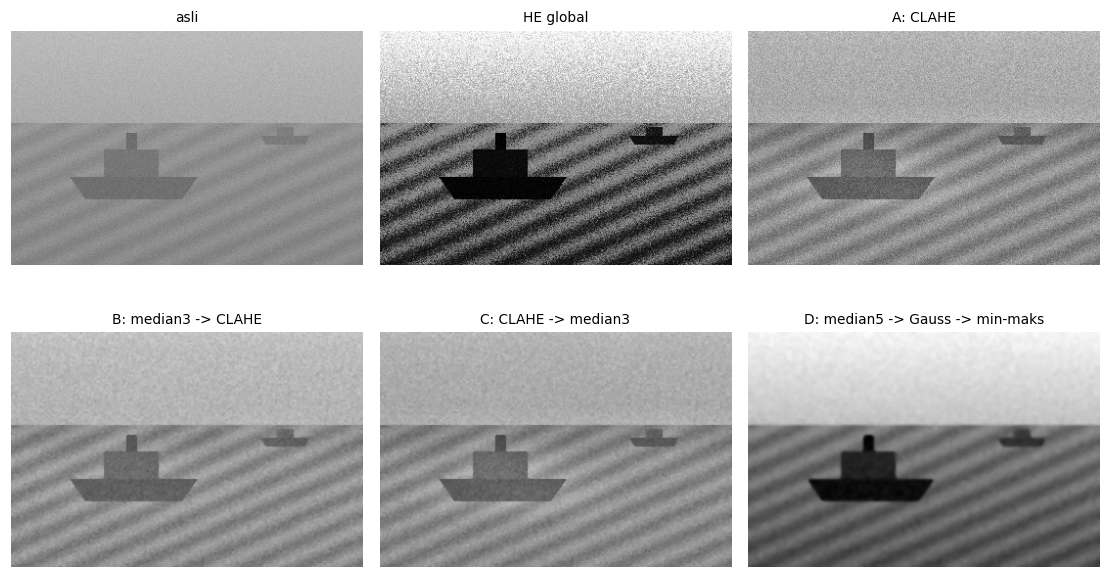

In [ ]:
# TODO 4.1 — CNR dan empat alur
kapal, laut = masker_perairan()
def cnr(im):
    im = im.astype(np.float64)
    return abs(im[kapal].mean() - im[laut].mean()) / im[laut].std()

def clahe(im, c=2): return cv2.createCLAHE(clipLimit=c, tileGridSize=(8, 8)).apply(im)
med3   = lambda im: cv2.medianBlur(im, 3)
med5   = lambda im: cv2.medianBlur(im, 5)
gauss  = lambda im: cv2.GaussianBlur(im, (5, 5), 1.0)
minmaks = lambda im: cv2.normalize(im, None, 0, 255, cv2.NORM_MINMAX)

alur = {
    'asli': perairan,
    'HE global': cv2.equalizeHist(perairan),
    'A: CLAHE': clahe(perairan),
    'B: median3 -> CLAHE': clahe(med3(perairan)),
    'C: CLAHE -> median3': med3(clahe(perairan)),
    'D: median5 -> Gauss -> min-maks': minmaks(gauss(med5(perairan))),
}
print(f'{"alur":32s} {"beda rerata":>11s} {"std laut":>9s} {"CNR":>6s}')
for n, im in alur.items():
    v = im.astype(float)
    print(f'{n:32s} {abs(v[kapal].mean() - v[laut].mean()):11.2f} {v[laut].std():9.2f} {cnr(im):6.2f}')

# Bukti Analisis 4(d): tiap langkah dijalankan sendiri-sendiri pada citra asli
for n, f in [('median 3x3', med3), ('median 5x5', med5), ('Gauss 5x5', gauss), ('CLAHE', clahe), ('min-maks', minmaks)]:
    print(f'{n:12s} sendiri: CNR {cnr(f(perairan)):.2f}')
tampil(list(alur.values()), list(alur.keys()), kolom=3)

**Analisis 4.** (a) Alur mana yang Anda pilih dan berapa CNR-nya? (b) Apakah urutan B dan C memberi angka yang sama? Jelaskan penyebabnya. (c) Mengapa HE global atau CLAHE saja bisa menaikkan beda rerata tetapi tidak selalu menaikkan CNR? (d) Bagian mana dari alur terbaik Anda yang sesungguhnya menaikkan CNR? Buktikan dengan menjalankan setiap langkahnya **sendiri-sendiri**. (e) Satu kalimat: apa yang **tidak** dapat Anda klaim dari percobaan ini tentang deteksi kapal sungguhan?

*Jawaban Anda:*

**(a)** Alur D median 5×5 → Gauss 5×5 → min–maks, CNR 4,20 dibanding 3,25 pada citra asli. Alur A, B, dan C semuanya di bawah citra asli 2,14; 2,81; 2,70. D saya rancang setelah melihat hasil di citra yang sama, jadi angkanya cenderung optimistis.

**(b)** Tidak sama: B = 2,81, C = 2,70. Median dan CLAHE sama-sama nonlinier sehingga urutannya tidak dapat ditukar. Pada B, derau diredam lebih dulu sehingga CLAHE bekerja pada histogram yang lebih bersih dan beda rerata lebih besar 40,12 vs 37,84 Ini dugaan yang konsisten dengan angka, belum saya uji terpisah.

**(c)** HE global menaikkan beda rerata dari 24,02 menjadi 72,63, tetapi std laut ikut naik dari 7,39 menjadi 39,91, sehingga CNR turun ke 1,82. CLAHE A menaikkan beda rerata ke 38,32 tetapi std laut ke 17,95, sehingga CNR 2,14. Dugaan saya, HE paling curam di aras yang paling padat laut, jadi variasi di dalam laut diperbesar lebih banyak daripada selisih kapal-laut. Peregangan min–maks yang linear tidak mengubah CNR 3,24, karena pembilang dan penyebut dikali faktor yang sama.

**(d)** Dijalankan sendiri-sendiri pada citra asli CNR 3,25: median 5×5 = 4,16; Gauss 5×5 = 3,98; min–maks = 3,24. Jadi kenaikan pada D hampir seluruhnya berasal dari median 5×5 3,25 → 4,16; Gauss dan min–maks hanya menambah sekitar 0,04 D = 4,20. Median menurunkan std laut tanpa banyak mengubah beda rerata. Sebaliknya, CLAHE sendiri menurunkan CNR menjadi 2,14.

**(e)** Percobaan ini hanya menunjukkan perubahan CNR pada satu citra sintetis, dan tidak membuktikan apa pun tentang kinerja deteksi kapal pada citra kamera atau satelit sungguhan.

---
## Bagian 5 &mdash; Daftar periksa sebelum mengumpulkan (10 menit)

- [x] Uji cepat TODO 1.1 mencetak `True` semua
- [x] Pemetaan contoh 8 aras = `[1 3 5 6 6 7 7 7]` dan spesifikasi = `[2 3 5 6 6 7 7 7]`
- [x] `lut_he_cdfmin` menghasilkan **0 piksel berbeda** dari `cv2.equalizeHist` pada kedua citra
- [x] Korelasi buatan sendiri cocok dengan `cv2.filter2D` (selisih < 1e-9)
- [x] Setiap blok Analisis memuat angka dari keluaran Anda sendiri
- [x] Penggunaan alat bantu AI (bila ada) dicantumkan: alat apa, bagian mana, cara Anda memeriksa kebenarannya
- [x] Berkas dinamai `PraktikumPCD_SubCPMK2_NIM_Nama.ipynb` dan sudah dijalankan penuh

**Penggunaan AI:**
1. claude -> (2.1)  memperbaiki code yang error dari contoh PCD_Praktikum_Dataset_EDA_Preprocessing_.ipynb bagian 7A2, AI digunakan karena terdapat error pada kode akibat adanya perbedaan dataset dan metode perbaikan citra.
2. claude -> (2.3 - 2.6) membantu menyusun TODO. AI digunakan untuk membantu dalam menyusun TODO pada bagian 2.3 hingga 2.6
3. claude -> (3.1) memperbaiki code yang error dari contoh PCD_Praktikum_Dataset_EDA_Preprocessing_.ipynb bagian 7B1, AI digunakan karena terdapat error pada kode akibat adanya perbedaan dataset dan metode perbaikan citra.
4. claude -> (3.3) membantu menyusun TODO. AI digunakan untuk membantu dalam menyusun TODO pada bagian 3.3
5. claude -> (4.1) membantu menyusun TODO. AI digunakan untuk membantu dalam menyusun TODO pada bagian 4.1
5. claude -> (analisis 1-4) AI membantu menjawaba lalu ditulis ulang dengan pemahaman sendiri

**Cara memeriksa kebenarannya:**
- Menjalankan ulang secara penuh di notebook dan angka pada setiap Analisis diambil dari keluaran yang dihasilkan.
- Hasil dicocokkan dengan contoh hitung tangan dari modul
- Membandingkan implementasi dengan fungsi pustaka cv2.equalizeHist